# Descriptive statistics and correlations

This notebook combines all explanatory variables into one table per municipality, summarises them and shows how they correlate with charging point density and with each other. The correlation table is the starting point for the regression in section 7: strongly correlated explanatory variables point to possible multicollinearity.

**Folder structure:** this notebook sits in `notebooks/` and reads from `data/raw/`. Outputs go to `data/processed/` and `figures/`.

**Input files in `data/raw/`:**
- `laadpunten_per_gemeente.csv`: regular public charging points per municipality, July 2026 (NAL)
- `inkomens_per_gemeente.csv`: households and standardised income per municipality, 2024 (CBS 86161NED)
- `jongeren_per_gemeente_2026.csv` and `ouderen_per_gemeente_2026.csv`: age structure (CBS)
- `tk2025_uitslag.csv`: results of the Tweede Kamer election of 29 October 2025 (Kiesraad, CSV ZIP on data.overheid.nl)
- `kwb2024_per_gemeente.csv`: education, population density and share of apartments per municipality, extracted from CBS Kerncijfers wijken en buurten 2024 (85984NED). If it is missing, it is created from the full CBS download in `data/raw/kwb2024/`.

**Outputs:**
- `data/processed/alle_variabelen_per_gemeente.csv`: all variables in one table, input for the regression (section 7)
- `data/processed/tabel_vergelijking_factoren.csv`: Table 3 of the report
- `figures/figuur_correlatiematrix.png` and `figures/figuur_verdeling_laadpunten.png`

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## 1. Load and merge the data

CBS writes some municipality names differently from the charging point data, for example *'s-Gravenhage* instead of *Den Haag*. These names are aligned before merging.

In [2]:
NAME_MAPPING = {
    "'s-Gravenhage (gemeente)": "Den Haag",
    "'s-Gravenhage": "Den Haag",
    "Groningen (gemeente)": "Groningen",
    "Utrecht (gemeente)": "Utrecht",
    "Beek (L.)": "Beek",
    "Stein (L.)": "Stein",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Hengelo (O)": "Hengelo",
    "Bergen (L)": "Bergen (L.)",
    "Bergen (NH)": "Bergen (NH.)",
}


RAW = "../data/raw/"
PROCESSED = "../data/processed/"
FIGURES = "../figures/"


def clean_names(series):
    """Strip spaces and align CBS municipality names with the charging point data."""
    return series.str.strip().replace(NAME_MAPPING)


# Charging points (NAL, July 2026) and households and income (CBS 86161NED, 2024)
charging = pd.read_csv(RAW + "laadpunten_per_gemeente.csv", sep=";")
charging.columns = ["gemeente", "laadpunten"]
charging = charging[charging["gemeente"] != "Totaal"]
charging["gemeente"] = clean_names(charging["gemeente"])

income = pd.read_csv(RAW + "inkomens_per_gemeente.csv", sep=";", encoding="utf-8-sig")
for col in income.columns[4:]:
    income[col] = pd.to_numeric(income[col].astype(str).str.strip(), errors="coerce")
income = pd.DataFrame({
    "gemeente": clean_names(income["Regio's"]),
    "huishoudens_x1000": income["Particuliere huishoudens (x 1 000)"],
    "gem_gestandaardiseerd_inkomen_keur": income["Inkomen/Gemiddeld gestandaardiseerd inkomen (1 000 euro)"],
    "med_gestandaardiseerd_inkomen_keur": income["Inkomen/Mediaan gestandaardiseerd inkomen (1 000 euro)"],
})

df = charging.merge(income, on="gemeente", how="inner")
df["laadpunten_per_1000_huishoudens"] = df["laadpunten"] / df["huishoudens_x1000"]  # households are in thousands
df = df[["gemeente", "laadpunten_per_1000_huishoudens",
         "gem_gestandaardiseerd_inkomen_keur", "med_gestandaardiseerd_inkomen_keur"]]

# Age structure
young = pd.read_csv(RAW + "jongeren_per_gemeente_2026.csv", sep=";", decimal=",", encoding="utf-8-sig")
old = pd.read_csv(RAW + "ouderen_per_gemeente_2026.csv", sep=";", decimal=",", encoding="utf-8-sig")
young = pd.DataFrame({"gemeente": clean_names(young["Gemeente"]), "jongeren_onder_25_pct": young["Totaal, 0 tot 25"]})
old = pd.DataFrame({"gemeente": clean_names(old["Gemeente"]), "ouderen_65plus_pct": old["Totaal, 65 jaar of ouder"]})
df = df.merge(young, on="gemeente", how="left").merge(old, on="gemeente", how="left")

# Left-wing vote share, Tweede Kamer election 29 October 2025 (Kiesraad, TK2025_uitslag.csv)
# Left-wing = GroenLinks-PvdA, SP, Partij voor de Dieren, DENK, BIJ1, D66 and Volt.
# The narrow definition (without D66 and Volt) is kept as a robustness check.
LEFT_NARROW = ["GROENLINKS / Partij van de Arbeid (PvdA)", "SP (Socialistische Partij)",
               "Partij voor de Dieren", "DENK", "BIJ1"]
LEFT_BROAD = LEFT_NARROW + ["D66", "Volt"]

if os.path.exists(RAW + "tk2025_uitslag.csv"):
    tk = pd.read_csv(RAW + "tk2025_uitslag.csv", sep=";", dtype=str)
    tk = tk[tk["RegioCode"].str.startswith("G") & (tk["VeldType"] == "LijstAantalStemmen")].copy()
    tk["Waarde"] = tk["Waarde"].astype(int)
    per_party = tk.pivot_table(index="Regio", columns="LijstNaam", values="Waarde", aggfunc="sum").fillna(0)
    total_votes = per_party.sum(axis=1)
    votes = pd.DataFrame({
        "gemeente": clean_names(pd.Series(per_party.index)),
        "linkse_stemmen_pct": (per_party[LEFT_BROAD].sum(axis=1) / total_votes * 100).values,
        "linkse_stemmen_smal_pct": (per_party[LEFT_NARROW].sum(axis=1) / total_votes * 100).values,
    })
    df = df.merge(votes, on="gemeente", how="left")

# Education, population density and share of apartments (CBS Kerncijfers wijken en buurten 2024, 85984NED)
# The full CBS download (folder kwb2024/) is large, so a small extract per municipality is saved once
# and used from then on.
KWB_MEASURES = {
    "M000100": "bevolkingsdichtheid",   # inhabitants per km² land
    "ZW10340": "meergezinswoning_pct",  # apartments as % of housing stock
    "2018700": "opl_laag",              # persons 15-75, low education (basisonderwijs, vmbo, mbo1)
    "2018740": "opl_middel",            # persons 15-75, middle education (havo, vwo, mbo2-4)
    "2018790": "opl_hoog",              # persons 15-75, high education (hbo, wo)
}
EXTRACT = RAW + "kwb2024_per_gemeente.csv"

if not os.path.exists(EXTRACT) and os.path.exists(RAW + "kwb2024/Observations.csv"):
    obs = pd.read_csv(RAW + "kwb2024/Observations.csv", sep=";", dtype=str)
    obs = obs[obs["WijkenEnBuurten"].str.startswith("GM") & obs["Measure"].isin(KWB_MEASURES)]
    kwb = obs.pivot(index="WijkenEnBuurten", columns="Measure", values="Value").rename(columns=KWB_MEASURES)
    kwb = kwb.apply(pd.to_numeric, errors="coerce")
    names = pd.read_csv(RAW + "kwb2024/WijkenEnBuurtenCodes.csv", sep=";", dtype=str).set_index("Identifier")["Title"]
    kwb.insert(0, "gemeente", names.reindex(kwb.index).str.strip().values)
    kwb.index.name = "gemeentecode"
    kwb.reset_index().to_csv(EXTRACT, index=False)
    print("Saved:", EXTRACT)

if os.path.exists(EXTRACT):
    kwb = pd.read_csv(EXTRACT)
    kwb["gemeente"] = clean_names(kwb["gemeente"])
    educated = kwb[["opl_laag", "opl_middel", "opl_hoog"]].sum(axis=1)
    kwb["hoogopgeleid_pct"] = kwb["opl_hoog"] / educated * 100
    df = df.merge(kwb[["gemeente", "hoogopgeleid_pct", "bevolkingsdichtheid", "meergezinswoning_pct"]],
                  on="gemeente", how="left")

print("Municipalities:", len(df))
print("Variables:", list(df.columns[1:]))

Municipalities: 342
Variables: ['laadpunten_per_1000_huishoudens', 'gem_gestandaardiseerd_inkomen_keur', 'med_gestandaardiseerd_inkomen_keur', 'jongeren_onder_25_pct', 'ouderen_65plus_pct', 'linkse_stemmen_pct', 'linkse_stemmen_smal_pct', 'hoogopgeleid_pct', 'bevolkingsdichtheid', 'meergezinswoning_pct']


In [3]:
# Readable English labels for tables and figures
LABELS = {
    "laadpunten_per_1000_huishoudens": "Charging points per 1,000 households",
    "gem_gestandaardiseerd_inkomen_keur": "Mean standardised income (k€)",
    "med_gestandaardiseerd_inkomen_keur": "Median standardised income (k€)",
    "jongeren_onder_25_pct": "Residents under 25 (%)",
    "ouderen_65plus_pct": "Residents 65+ (%)",
    "linkse_stemmen_pct": "Left-wing vote share (%)",
    "linkse_stemmen_smal_pct": "Left-wing vote share, narrow (%)",
    "hoogopgeleid_pct": "Highly educated (%)",
    "bevolkingsdichtheid": "Population density (inh./km²)",
    "meergezinswoning_pct": "Apartments (% of dwellings)",
}
variables = [c for c in LABELS if c in df.columns]
data = df[variables].rename(columns=LABELS)

# Check for missing values per variable
missing = data.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values")

Mean standardised income (k€)      6
Median standardised income (k€)    3
dtype: int64


## 2. Descriptive statistics

The table shows the number of municipalities with data (N), the mean, the spread and the range of each variable.

In [4]:
summary = data.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
summary = summary.rename(columns={"count": "N", "std": "SD", "50%": "median"})
summary["N"] = summary["N"].astype(int)
summary.round(2)

,N,mean,SD,min,25%,median,75%,max
"Charging points per 1,000 households",342,15.01,6.77,0.54,9.95,13.54,19.32,42.88
Mean standardised income (k€),336,44.17,8.58,34.10,40.50,42.90,45.70,154.70
Median standardised income (k€),339,38.07,2.69,30.40,36.40,38.00,39.65,48.50
Residents under 25 (%),342,26.23,2.87,17.10,24.60,26.05,27.90,42.40
Residents 65+ (%),342,23.61,3.68,11.00,21.30,23.60,25.88,34.90
Left-wing vote share (%),342,31.04,10.96,1.94,24.04,30.00,36.23,71.24
"Left-wing vote share, narrow (%)",342,14.92,6.52,1.21,10.55,13.73,18.25,45.13
Highly educated (%),342,30.48,8.11,12.44,25.17,28.68,33.42,58.97
Population density (inh./km²),342,917.63,1090.64,23.00,249.00,479.00,1194.00,6868.00
Apartments (% of dwellings),342,23.90,13.23,2.00,15.00,20.00,30.00,87.00


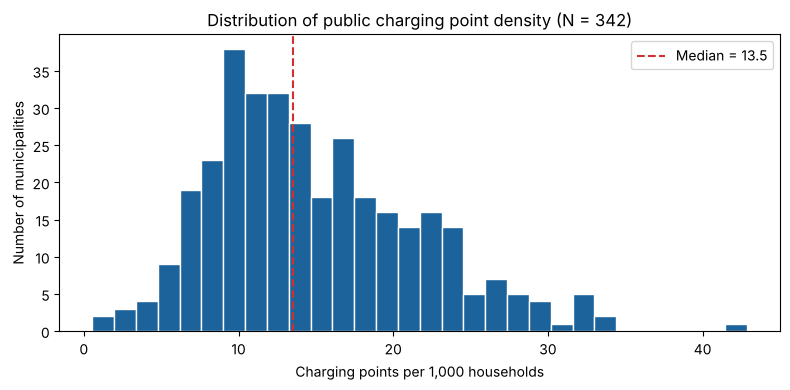

In [5]:
# Distribution of the dependent variable
fig, ax = plt.subplots(figsize=(8, 4))
y = data["Charging points per 1,000 households"]
ax.hist(y, bins=30, color="#1d639b", edgecolor="white")
ax.axvline(y.median(), color="#d32f2f", linestyle="--", label=f"Median = {y.median():.1f}")
ax.set_xlabel("Charging points per 1,000 households")
ax.set_ylabel("Number of municipalities")
ax.set_title("Distribution of public charging point density (N = %d)" % y.notna().sum())
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES + "figuur_verdeling_laadpunten.png", dpi=200)
plt.show()

## 3. Comparison of all factors (report section 6.6, Table 2)

For each explanatory variable the Pearson correlation (linear relation) and the Spearman correlation (rank-based, less sensitive to outliers) with charging point density are calculated. Municipalities with a missing value are left out per pair.

In [6]:
# Group of each explanatory variable, as used in Table 2 of the report
GROUPS = {
    "Mean standardised income (k€)": "Socioeconomic",
    "Median standardised income (k€)": "Socioeconomic",
    "Highly educated (%)": "Socioeconomic",
    "Residents under 25 (%)": "Demographic",
    "Residents 65+ (%)": "Demographic",
    "Population density (inh./km²)": "Need",
    "Apartments (% of dwellings)": "Need",
    "Left-wing vote share (%)": "Political",
    "Left-wing vote share, narrow (%)": "Political",
}

target = "Charging points per 1,000 households"
rows = []
for col in data.columns.drop(target):
    pair = data[[col, target]].dropna()
    r, p = stats.pearsonr(pair[col], pair[target])
    rho, p_rho = stats.spearmanr(pair[col], pair[target])
    rows.append({"Variable": col, "Group": GROUPS.get(col, ""), "N": len(pair),
                 "Pearson r": r, "p (Pearson)": p,
                 "Spearman ρ": rho, "p (Spearman)": p_rho,
                 "R²": r ** 2})

corr_target = pd.DataFrame(rows).sort_values("Pearson r", key=abs, ascending=False)
corr_target.style.format({"Pearson r": "{:.2f}", "Spearman ρ": "{:.2f}", "R²": "{:.3f}",
                          "p (Pearson)": "{:.3g}", "p (Spearman)": "{:.3g}"}).hide(axis="index")

Variable,Group,N,Pearson r,p (Pearson),Spearman ρ,p (Spearman),R²
Population density (inh./km²),Need,342,0.41,2.32e-15,0.51,1.76e-24,0.169
Apartments (% of dwellings),Need,342,0.34,8.16e-11,0.37,2.06e-12,0.117
Residents 65+ (%),Demographic,342,-0.34,8.53e-11,-0.38,2.98e-13,0.117
Median standardised income (k€),Socioeconomic,339,0.34,1.97e-10,0.34,2.15e-10,0.113
Highly educated (%),Socioeconomic,342,0.31,8.3e-09,0.33,2.1e-10,0.093
Residents under 25 (%),Demographic,342,0.29,4.31e-08,0.37,2.91e-12,0.085
Left-wing vote share (%),Political,342,0.22,4.26e-05,0.24,6.96e-06,0.048
Mean standardised income (k€),Socioeconomic,336,0.17,0.00141,0.34,2.52e-10,0.030
"Left-wing vote share, narrow (%)",Political,342,0.15,0.00422,0.14,0.00883,0.024


In [7]:
# Save Table 2 for the report
corr_target.round({"Pearson r": 3, "Spearman ρ": 3, "R²": 3}).to_csv(PROCESSED + "tabel_vergelijking_factoren.csv", index=False)
print("Saved:", PROCESSED + "tabel_vergelijking_factoren.csv")

Saved: ../data/processed/tabel_vergelijking_factoren.csv


## 4. Correlation matrix of all variables (report section 6.6, Figure 7)

The matrix shows how all variables relate to each other. Correlations above about 0.7 between two explanatory variables indicate that they measure partly the same thing, which can cause multicollinearity in the regression.

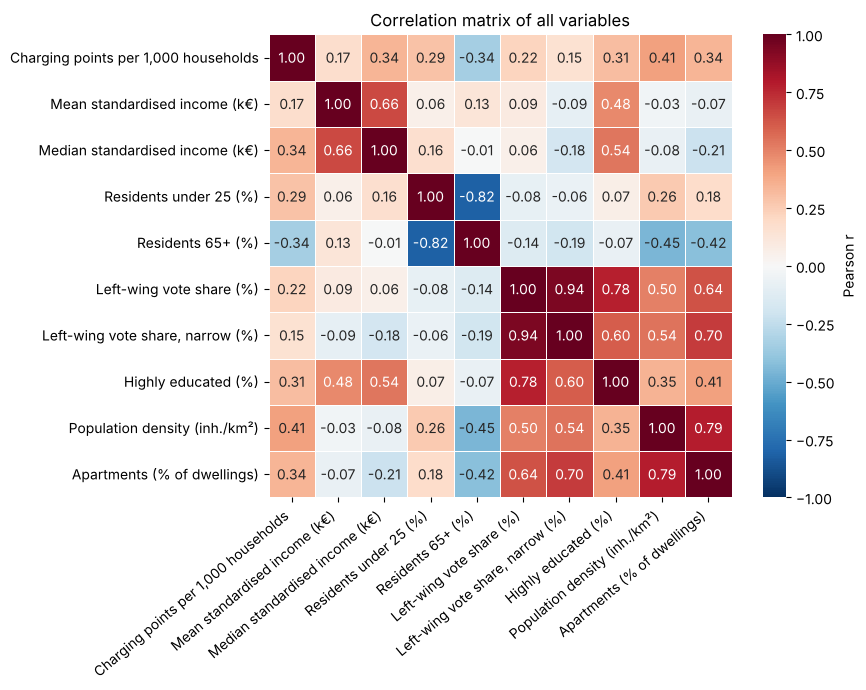

In [8]:
corr_matrix = data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of all variables")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(FIGURES + "figuur_correlatiematrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Pairs of explanatory variables with |r| > 0.7 (possible multicollinearity)
explanatory = corr_matrix.drop(index=target, columns=target)
pairs = [(a, b, explanatory.loc[a, b])
         for i, a in enumerate(explanatory.index)
         for b in explanatory.columns[i + 1:]
         if abs(explanatory.loc[a, b]) > 0.7]
if pairs:
    display(pd.DataFrame(pairs, columns=["Variable 1", "Variable 2", "Pearson r"]).round(2))
else:
    print("No pairs of explanatory variables with |r| > 0.7")

,Variable 1,Variable 2,Pearson r
0,Residents under 25 (%),Residents 65+ (%),-0.82
1,Left-wing vote share (%),"Left-wing vote share, narrow (%)",0.94
2,Left-wing vote share (%),Highly educated (%),0.78
3,"Left-wing vote share, narrow (%)",Apartments (% of dwellings),0.70
4,Population density (inh./km²),Apartments (% of dwellings),0.79


In [10]:
# Save the merged table for the regression notebook
df.to_csv(PROCESSED + "alle_variabelen_per_gemeente.csv", index=False)
print("Saved:", PROCESSED + "alle_variabelen_per_gemeente.csv")

Saved: ../data/processed/alle_variabelen_per_gemeente.csv
